# How hard will it rain?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/how_hard_will_it_rain.ipynb)

**The question:** *"How much rain can fall in a single day where I live, and is that getting worse?"*

Every year has one wettest day. Streets, drains and basements are built for a
certain amount of it. We answer the question three times, each with a better data
source, using the same open toolkit, [crc-sdk](https://github.com/RiskThinking/crc-sdk):

| | Data | What it can tell you |
|---|---|---|
| **A** | ERA5, the free global weather record (reanalysis) | What already happened, on a coarse grid |
| **B** | **CRC Open**: free, ready-made climate curves | What could happen in 2025–2090 under a high-emissions future (SSP5-8.5; [other futures on request](mailto:opensource@riskthinking.ai)) |
| **C** | **CDT**, Riskthinking.AI's Climate Digital Twin (enterprise) | Every emissions future and a matching historical baseline |

You can run this on Colab with **Runtime → Run all**. No account needed for A and B.
Change `CITY` in the setup cell to try another place.

## Setup

In [1]:
#@title Install packages (Colab) and choose a city
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        "crc-sdk[zarr,netcdf,geometry]>=0.11.1,<1", "plotly>=6,<7", "velo-sdk",
    ])

# Any city works: give a name and coordinates.
CITY = {"name": "Toronto, Canada", "latitude": 43.65, "longitude": -79.38}

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"
ERA5_YEARS = (2014, 2021) if CI else (1992, 2021)   # about 15 seconds per year
WINDOWS = {"2025–2045": (2025, 2030, 2035, 2040, 2045),
           "2050–2065": (2050, 2055, 2060, 2065),
           "2070–2090": (2070, 2075, 2080, 2085, 2090)}

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.parquet as pq

from crc_sdk.workflows import BlockExtremaPolicy, HazardDataset, curve_parameters_from_row

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"

DATA = Path("data") / "how_hard_rain"
DATA.mkdir(parents=True, exist_ok=True)

# One colour per idea, used the same way in every chart.
PAST = "#52514e"                                    # what was recorded
WINDOW_COLORS = dict(zip(WINDOWS, ("#9ec5f0", "#2a78d6", "#123f75")))  # light to dark = later
CDT_COLORS = {"historic": "#52514e", "ssp126": "#2a78d6", "ssp245": "#1baf7a", "ssp585": "#eb6834"}
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)
RP_TICKS = [1, 2, 5, 10, 20, 50, 100]
rp_grid = np.geomspace(1.2, 100, 200)


def curve_values(distribution, return_periods):
    """Evaluate a curve at return periods (years)."""
    return np.asarray(distribution.quantiles((1 - 1 / np.asarray(return_periods)).tolist()), dtype=float)


def return_period_of(levels, value, grid=rp_grid):
    """Read an averaged curve backwards: how often is `value` reached?"""
    return float(np.exp(np.interp(value, levels, np.log(grid))))


def layout(fig, title, **kwargs):
    fig.update_layout(title=dict(text=title, x=0.01), font=FONT, height=430,
                      margin=dict(l=70, r=30, t=70, b=60), **kwargs)
    return fig


def log_rp_axis(**kwargs):
    return dict(type="log", title="Return period (years, log scale)", tickvals=RP_TICKS, **kwargs)

## A. Ask the weather record

[ERA5](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels)
is the world's most used free weather record: decades of hourly weather on a
global grid, rebuilt from observations and a weather model (CC BY 4.0). crc-sdk
reads a public copy anonymously and keeps only the **wettest day of each year**
for the grid cell around `CITY`. This free copy has a 1.5° grid (about 165 km
across) and ends in 2021.

In [3]:
era5_plan = (
    HazardDataset.era5("rx1day", store="wb2-1p5")
    .for_area((CITY["longitude"] - 0.1, CITY["latitude"] - 0.1,
               CITY["longitude"] + 0.1, CITY["latitude"] + 0.1))
    .years(*ERA5_YEARS)
    .cache(DATA / "era5", mode="reuse")
    .canonicalize(policy=BlockExtremaPolicy.curated(h3_resolution=5, minimum_years=8 if CI else 20))
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    annual = era5_plan.annual_extremes().to_pandas()
    era5_plan.materialize(DATA / "era5_rx1day.parquet")

# Use the ERA5 grid cell that contains the city for both the curve and the yearly values.
from shapely import wkb
from shapely.geometry import Point

city_point = Point(CITY["longitude"], CITY["latitude"])
era5_rows = [row for row in pq.read_table(DATA / "era5_rx1day.parquet").to_pylist() if row["curve_kind"] != "no_data"]
era5_row = min(era5_rows, key=lambda row: wkb.loads(row["source_geometry"]).distance(city_point))
grid_cell = wkb.loads(era5_row["source_geometry"])
inside = [grid_cell.covers(Point(x, y)) for x, y in zip(annual["longitude"], annual["latitude"])]
annual = annual[inside].dropna(subset=["value"])
era5_curve = curve_parameters_from_row(era5_row).to_distribution()
wettest = annual.loc[annual["value"].idxmax()]
print(f"ERA5 grid point {annual['latitude'].iloc[0]:.1f}, {annual['longitude'].iloc[0]:.1f}: "
      f"{len(annual)} years, wettest day {wettest['value']:.0f} mm in {int(wettest['year'])}")

ERA5 grid point 43.5, -79.5: 30 years, wettest day 57 mm in 2004


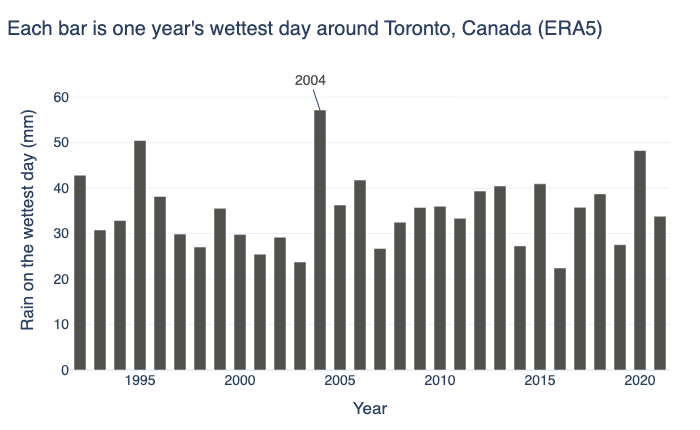

In [4]:
fig = go.Figure(go.Bar(
    x=annual["year"], y=annual["value"], marker_color=PAST, width=0.6,
    hovertemplate="%{x}: wettest day %{y:.0f} mm<extra></extra>",
))
fig.add_annotation(x=int(wettest["year"]), y=wettest["value"], text=f"{int(wettest['year'])}",
                   showarrow=True, arrowhead=0, ay=-30, font=dict(color=PAST))
layout(fig, f"Each bar is one year's wettest day around {CITY['name']} (ERA5)",
       xaxis_title="Year", yaxis_title="Rain on the wettest day (mm)", showlegend=False)
fig.show()

Notice how modest even the tallest bar is. Rain gauges in a city often record
much more on their worst days than ERA5 shows. That is not an error:

> 💡 **Key idea: a grid cell is an average over an area.** A storm that drowns
> one neighbourhood and spares the next gets **spread out** over the whole cell,
> like a spoonful of syrup stirred into a big pot. The bigger the cell, the
> weaker the peak looks. ERA5's free copy uses cells about 165 km wide, so it
> **underestimates** local downpours.

As with any short record, crc-sdk **fits a curve** through the yearly values (a
GEV distribution, the standard choice for yearly extremes), so we can talk about
rarer days than the record contains:

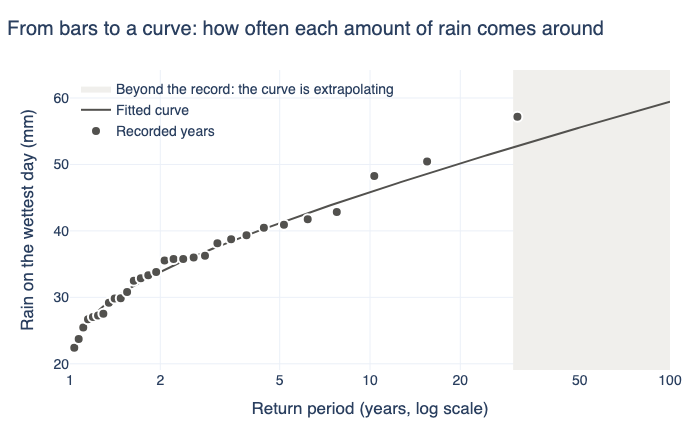

,return period,wettest day (mm)
0,2,34.0
1,10,46.0
2,25,52.0
3,100,59.0


In [5]:
def show_era5_curve():
    values = np.sort(annual["value"].to_numpy())
    plotting_rp = (len(values) + 1) / np.arange(len(values), 0, -1)  # Weibull plotting positions
    record_years = len(values)
    low, high = values.min() * 0.85, max(values.max(), curve_values(era5_curve, [100])[0]) * 1.08

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=[record_years, 100, 100, record_years], y=[low, low, high, high], fill="toself",
                             fillcolor="#f0efec", line_width=0, mode="lines", hoverinfo="skip",
                             name="Beyond the record: the curve is extrapolating"))
    fig.add_trace(go.Scatter(x=rp_grid, y=curve_values(era5_curve, rp_grid), mode="lines",
                             name="Fitted curve", line=dict(color=PAST, width=2)))
    fig.add_trace(go.Scatter(x=plotting_rp, y=values, mode="markers", name="Recorded years",
                             marker=dict(size=10, color=PAST, line=dict(width=2, color="white")),
                             hovertemplate="%{y:.0f} mm, about 1-in-%{x:.0f} years<extra></extra>"))
    layout(fig, "From bars to a curve: how often each amount of rain comes around",
           xaxis=log_rp_axis(range=[0, 2]), yaxis=dict(title="Rain on the wettest day (mm)", range=[low, high]),
           legend=dict(x=0.01, y=0.99, bgcolor="rgba(0,0,0,0)"))
    fig.show()
    table = pd.DataFrame({"return period": [2, 10, 25, 100]})
    table["wettest day (mm)"] = curve_values(era5_curve, table["return period"]).round(0)
    return table


show_era5_curve()

**What A tells us, and what it can't:**

- ✅ Free, global and consistent: the same method everywhere on Earth.
- ❌ **Only the past.** The record stops in 2021 (in this free copy).
- ❌ **Blurry.** A 165 km cell smooths out the downpours that flood streets.
- ❌ **Short record.** Anything rarer than about 1-in-30 years is extrapolated (shaded).

## B. Ask CRC Open

[CRC Open](https://github.com/RiskThinking/crc-sdk/blob/main/docs/sources/crc-open.md)
is a free public release of ready-made climate curves for 63 hazards worldwide,
built from bias-corrected climate models
([CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/)). For rain it
offers `rx1day`, the wettest day of the year, on hexagons of about 250 km²
(roughly 100 times smaller than the ERA5 cell above), every five years from 2025
to 2090. There is nothing to fit: crc-sdk downloads only the area you ask for,
checks its checksum, and hands you the curves.

This public release covers one high-emissions future, SSP5-8.5. Lower-emissions
futures are available too: [ask the open-source team](mailto:opensource@riskthinking.ai).

In [6]:
horizons = [h for window in WINDOWS.values() for h in window]
crc_plan = (
    HazardDataset.crc_open()
    .for_area((CITY["longitude"] - 0.05, CITY["latitude"] - 0.05,
               CITY["longitude"] + 0.05, CITY["latitude"] + 0.05))
    .hazards(["rx1day"])
    .horizons(horizons)
    .cache(DATA / "crc-open", mode="reuse")
)
selection = crc_plan.resolve()
print(f"Downloading {selection.total_bytes / 1e6:.0f} MB once (cached afterwards)")

city = pa.table({"asset_id": [CITY["name"]], "longitude": [CITY["longitude"]], "latitude": [CITY["latitude"]]})
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    crc_plan.for_assets(city).return_periods([2]).write_parquet(DATA / "city_rx1day.parquet")
    crc_plan.materialize(DATA / "rx1day.parquet")

matched_cell = pq.read_table(DATA / "city_rx1day.parquet").column("cell_index")[0].as_py()
rows = [row for row in pq.read_table(DATA / "rx1day.parquet").to_pylist()
        if row["cell_index"] == matched_cell and row["curve_kind"] != "no_data"]
future = {row["horizon"]: curve_parameters_from_row(row).to_distribution() for row in rows}
levels = {h: curve_values(future[h], rp_grid) for h in sorted(future)}
print(f"{len(future)} horizons from {min(future)} to {max(future)} | scenario: {rows[0]['pathway']}")

14 horizons from 2025 to 2090 | scenario: ssp585


CRC Open gives one curve every five years. Plot them all and something stands
out: **they wobble**. A single horizon is estimated from a limited sample of
model years, and rain is the jumpiest weather there is. So, like a weather
forecaster reading many runs, we **average the curves within each window** of
years (bold lines) and compare windows, not single years.

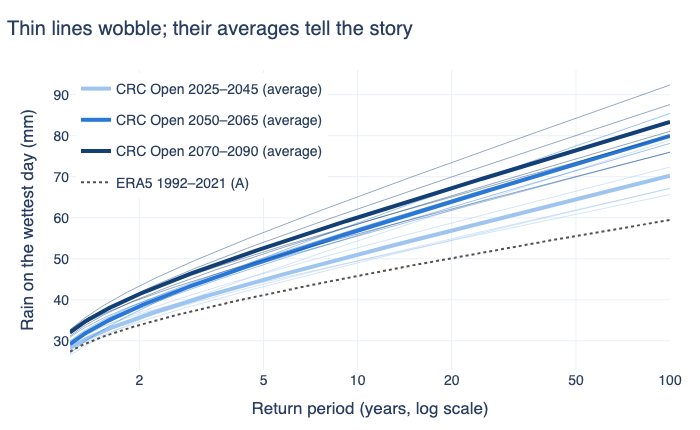

In [7]:
window_levels = {name: np.mean([levels[h] for h in years if h in levels], axis=0)
                 for name, years in WINDOWS.items()}

fig = go.Figure()
for name, years in WINDOWS.items():
    for i, h in enumerate(h for h in years if h in levels):
        fig.add_trace(go.Scatter(x=rp_grid, y=levels[h], mode="lines", line=dict(color=WINDOW_COLORS[name], width=1),
                                 opacity=0.45, name=f"Single horizons {name}", legendgroup=name,
                                 showlegend=False, hovertemplate=f"{h}: %{{y:.0f}} mm<extra></extra>"))
    fig.add_trace(go.Scatter(x=rp_grid, y=window_levels[name], mode="lines", line=dict(color=WINDOW_COLORS[name], width=4),
                             name=f"CRC Open {name} (average)", legendgroup=name))
fig.add_trace(go.Scatter(x=rp_grid, y=curve_values(era5_curve, rp_grid), mode="lines",
                         name=f"ERA5 {ERA5_YEARS[0]}–{ERA5_YEARS[1]} (A)", line=dict(color=PAST, width=2, dash="dot")))
layout(fig, "Thin lines wobble; their averages tell the story",
       xaxis=log_rp_axis(), yaxis_title="Rain on the wettest day (mm)", legend=dict(x=0.01, y=0.99))
fig.show()

The dotted ERA5 line sits below every CRC Open curve: partly because its big
cells blur downpours (A), partly because the climate has already shifted since
the years ERA5 covers.

> 💡 **Key idea: the rarer the event, the less sure the number.** Within each
> window, the thin lines sit closer together on the left (a typical year) and
> spread apart to the right (a once-a-century day). It's like guessing heights:
> easy for an average person, harder for the tallest person in a crowd you've
> only glimpsed. The chart below measures that spread.

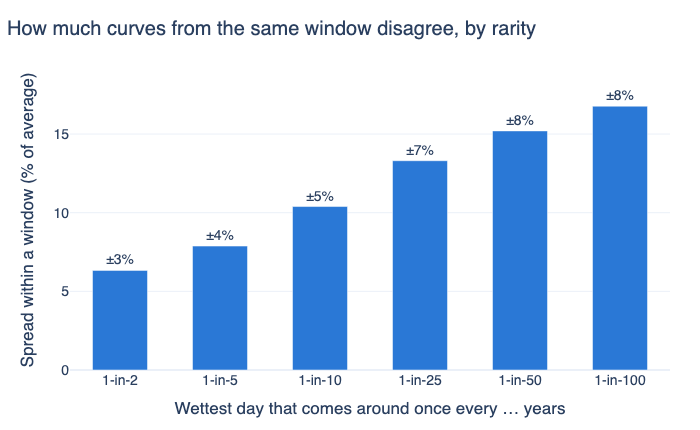

In [8]:
spread_rps = [2, 5, 10, 25, 50, 100]
spread = []
for rp in spread_rps:
    # Spread among horizons in the same window (not the climate trend between windows), averaged over windows.
    per_window = []
    for years in WINDOWS.values():
        values = np.array([curve_values(future[h], [rp])[0] for h in years if h in future])
        per_window.append(100 * (values.max() - values.min()) / values.mean())
    spread.append(float(np.mean(per_window)))

fig = go.Figure(go.Bar(
    x=[f"1-in-{rp}" for rp in spread_rps], y=spread, marker_color="#2a78d6", width=0.55,
    text=[f"±{s / 2:.0f}%" for s in spread], textposition="outside", cliponaxis=False,
    hovertemplate="%{x} years: horizons in a window span %{y:.0f}% of their average<extra></extra>",
))
layout(fig, "How much curves from the same window disagree, by rarity",
       xaxis_title="Wettest day that comes around once every … years",
       yaxis=dict(title="Spread within a window (% of average)", rangemode="tozero"), showlegend=False)
fig.show()

That is why this notebook's headline uses the **1-in-10-year downpour**: rare
enough to matter for drains and basements, common enough to estimate well.
Planning for once-a-century rain needs the full curve *and* its uncertainty,
which CRC curves carry with them.

### The answer, in one picture

Take the early window's **1-in-10-year wettest day** and ask how often that much
rain falls in later windows.

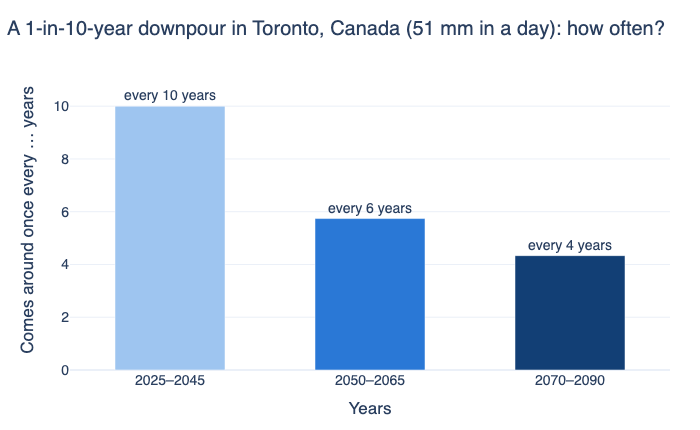

The 1-in-10-year wettest day grows from about 51 mm (2025–2045) to about 60 mm (2070–2090), +18%.


In [9]:
names = list(WINDOWS)
threshold = float(np.interp(10, rp_grid, window_levels[names[0]]))
new_rp = {name: return_period_of(window_levels[name], threshold) for name in names}
late_10 = float(np.interp(10, rp_grid, window_levels[names[-1]]))

fig = go.Figure(go.Bar(
    x=names, y=[new_rp[n] for n in names], marker_color=[WINDOW_COLORS[n] for n in names], width=0.55,
    text=[f"every {new_rp[n]:.0f} years" for n in names], textposition="outside", cliponaxis=False,
    hovertemplate="%{x}: once every %{y:.1f} years<extra></extra>",
))
layout(fig, f"A 1-in-10-year downpour in {CITY['name']} ({threshold:.0f} mm in a day): how often?",
       yaxis=dict(title="Comes around once every … years", rangemode="tozero"), xaxis_title="Years", showlegend=False)
fig.show()
print(f"The 1-in-10-year wettest day {'grows' if late_10 > threshold else 'shrinks'} from about {threshold:.0f} mm ({names[0]}) "
      f"to about {late_10:.0f} mm ({names[-1]}), {100 * (late_10 / threshold - 1):+.0f}%.")

In plain words: **the kind of downpour that now comes about once a decade comes
noticeably more often later this century** under this scenario, and the
heaviest days get heavier.

**What B adds over A:** the future, curves on a grid about 100 times finer, no
fitting, and the same format for 63 hazards worldwide.

**What B leaves out:** CRC Open covers one emissions pathway, **SSP5-8.5** (high
emissions), and has no matching historical baseline, so "how much worse than the
past" mixes sources (ERA5 vs models). Need other pathways or a baseline for
planning or disclosure? See part C, or ask [opensource@riskthinking.ai](mailto:opensource@riskthinking.ai) about more CRC Open data.

## C. Ask CDT

**CDT** (Climate Digital Twin) is Riskthinking.AI's enterprise service. For any
location it returns curves for **every emissions pathway** (SSP1-2.6 to SSP5-8.5,
plus warming levels), a **historical baseline** from the same models, and the
**financial impact** on buildings, plus asset, company and market-index views.

Here we compare the historical baseline (around 2010) with the late-century
window (2070–2090, averaged as in B) under three futures.

The saved results below come from a CDT run: a small table of return levels
and one chart. To run it yourself you need an API key; [start a CDT Express trial](https://velo.riskthinking.ai/cdt-express)
to get one. In Colab, store it as a secret named `RISKTHINKING_API_KEY`. Without a
key the cells explain how to get one and skip.

Prefer chatting to coding? Connect the [CDT Express MCP server](https://github.com/RiskThinking/cdt-express-mcp)
to Claude or ChatGPT and ask: *"How much rain can fall in one day in Toronto, historically and by 2080?"*

In [10]:
api_key = os.environ.get("RISKTHINKING_API_KEY")
if api_key is None and IN_COLAB:
    from google.colab import userdata
    try:
        api_key = userdata.get("RISKTHINKING_API_KEY")
    except Exception:
        api_key = None

CDT_RPS = (2, 5, 10, 25)
cdt = None
if api_key:
    from velo_sdk.api import APIClient

    client = APIClient(api_key=api_key)
    requests = [("historic", 2010)] + [(p, h) for p in ("ssp126", "ssp245", "ssp585") for h in (2070, 2080, 2090)]
    records = []
    for pathway, horizon in requests:
        response = client.get("/v4/climate/metrics/exposure", params={
            "latitude": CITY["latitude"], "longitude": CITY["longitude"], "risk_factor": "rx1day",
            "pathway": pathway, "horizon": str(horizon), "return_periods": ",".join(map(str, CDT_RPS)),
        })
        for result in response["results"]:
            if result["index_name"] != "rx1day":
                continue
            for rp, value in result["exposure_return_periods"].items():
                records.append({"pathway": pathway, "return_period": int(rp), "wettest_day_mm": float(value)})
    # Average the late-century horizons, as in B.
    cdt = pd.DataFrame(records).groupby(["pathway", "return_period"], as_index=False)["wettest_day_mm"].mean()
    display(cdt.pivot_table(index="return_period", columns="pathway", values="wettest_day_mm").round(0))
else:
    print("No RISKTHINKING_API_KEY found, so section C is skipped.")
    print("Start a trial at https://velo.riskthinking.ai/cdt-express.")

pathway,historic,ssp126,ssp245,ssp585
return_period,,,,
2,31.0,36.0,38.0,41.0
5,38.0,47.0,48.0,52.0
10,43.0,55.0,55.0,60.0
25,47.0,66.0,63.0,70.0


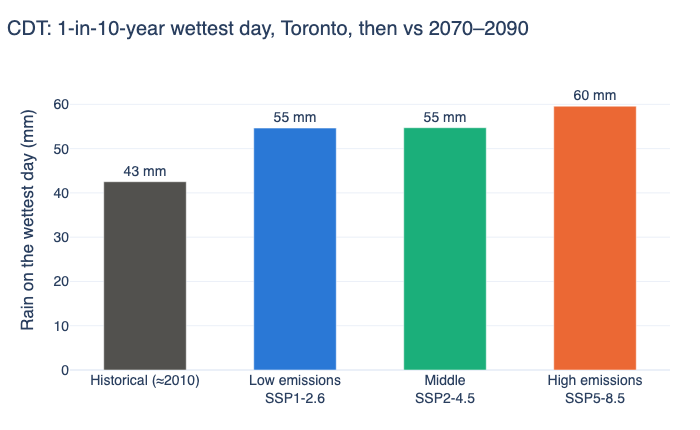

1-in-10-year wettest day: 43 mm in the historical baseline; in 2070–2090 55 mm (SSP1-2.6), 55 mm (SSP2-4.5) and 60 mm (SSP5-8.5).


In [11]:
if cdt is not None:
    ten = cdt[cdt["return_period"] == 10].set_index("pathway")["wettest_day_mm"]
    labels = {"historic": "Historical (≈2010)", "ssp126": "Low emissions<br>SSP1-2.6",
              "ssp245": "Middle<br>SSP2-4.5", "ssp585": "High emissions<br>SSP5-8.5"}
    order = [p for p in CDT_COLORS if p in ten.index]
    fig = go.Figure(go.Bar(
        x=[labels[p] for p in order], y=[ten[p] for p in order], marker_color=[CDT_COLORS[p] for p in order],
        width=0.55, text=[f"{ten[p]:.0f} mm" for p in order], textposition="outside", cliponaxis=False,
        hovertemplate="%{x}: %{y:.0f} mm<extra></extra>",
    ))
    layout(fig, f"CDT: 1-in-10-year wettest day, {CITY['name'].split(',')[0]}, then vs 2070–2090",
           yaxis=dict(title="Rain on the wettest day (mm)", rangemode="tozero"), showlegend=False)
    fig.show()
    print(f"1-in-10-year wettest day: {ten['historic']:.0f} mm in the historical baseline; "
          f"in 2070–2090 {ten['ssp126']:.0f} mm (SSP1-2.6), {ten['ssp245']:.0f} mm (SSP2-4.5) "
          f"and {ten['ssp585']:.0f} mm (SSP5-8.5).")

Every future is wetter than the historical baseline, and the high-emissions
future is wettest. The lower pathways can swap places at a single location:
rain is noisy, and differences of a few millimetres are within that noise.

**What C adds over B:**

- **A matching historical baseline**, so "how much worse than before" compares
  like with like (in B we had to borrow ERA5, with its blurry grid).
- **Every pathway**, so you can show how much cutting emissions matters.
- **Financial impact** on buildings (`/v4/climate/metrics/impact`), not only rain.
- **Assets, companies and market indexes** already mapped, for portfolios.

## Recap

| | A. ERA5 | B. CRC Open | C. CDT |
|---|---|---|---|
| Past | ✅ recorded (coarse) | ➖ not included | ✅ modelled baseline |
| Future | ❌ | ✅ 2025–2090 | ✅ 2025–2100 |
| Detail | ~165 km cells | ~250 km² hexagons | ~250 km² hexagons |
| Emissions pathways | ❌ | SSP5-8.5 ([others on request](mailto:opensource@riskthinking.ai)) | All, plus warming levels |
| Financial impact | ❌ | Bring your own curve | ✅ built in |
| Cost | Free | Free (non-commercial) | [Trial](https://velo.riskthinking.ai/cdt-express), then licence |

**Next steps:** change `CITY` and run again; run the same analysis headlessly with
[`pipelines/how_hard_will_it_rain.py`](https://github.com/RiskThinking/crc-docs/blob/main/pipelines/how_hard_will_it_rain.py);
or ask an AI assistant with the [heavy-rain skill](https://github.com/RiskThinking/crc-docs/blob/main/.agents/skills/how-hard-will-it-rain/SKILL.md).

*Data: ERA5 by Copernicus Climate Change Service (CC BY 4.0), via the WeatherBench 2 copy;
CRC Open by Riskthinking.AI (CC BY-NC 4.0); CDT by Riskthinking.AI (licensed).*